# ZD3D — Training and Evaluation

Level-set PINN for 3D linear transport of a **Zalesak slotted sphere**: a
sphere of radius 0.15 with a rectangular slot of half-extents
(0.025, 0.125, 0.10), carried by solid-body rotation about the vertical axis
through (0.5, 0.5). One full revolution completes at t = T = 2*pi, so the shape
returns to its starting position and the error at t=T measures accumulated
drift over a closed orbit.

The slot has **finite depth in z**, so it is a blind pocket: a section near the
pole shows an unbroken sphere while a section through the middle shows the
notch. Fig. D (cutaway) makes this visible.

**Note on the exact solution.** The initial field is the CSG difference
`max(phi_sphere, -phi_slot)`, which is *not* an exact signed-distance function
near the slot's reentrant edges — it returns the distance to the nearer face
rather than to the edge. So `|grad phi| != 1` there in the exact solution, and
the eikonal term genuinely competes with the initial-condition term in those
neighbourhoods. This is why this benchmark wants a far smaller eikonal weight
than the plain-sphere cases.

**Runtime:** longer than the sphere benchmarks — Fourier features, RAD/RAR
resampling, and causal weighting all add per-iteration cost. Measure your first
run and update `EST_MIN_PER_RUN` in the ablation notebook.

**If `ZD3D_pretrained.pth` is present, training is skipped** and the notebook
goes straight to evaluation and figures.

**Outputs:** metrics table, `zd3d_interface.pdf`, `zd3d_verification.pdf`,
`zd3d_growth.pdf`, `zd3d_loss_history.pdf`, `zd3d_cutaway.pdf`, and one row appended to
`ZD3D_results.csv`.

All definitions live in `zd3d_core.py`, shared with
`01_eikonal_ablation.ipynb`.

In [1]:
# --- setup ---
# Put zd3d_core.py in the same Drive folder as this notebook.
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ZD3D'
except ImportError:
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)
os.makedirs(PROJECT_DIR, exist_ok=True)

import numpy as np
import torch
import time
import zd3d_core as core

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

Mounted at /content/drive
device: cuda Tesla T4


## Configuration

In [2]:
# --- configuration ---
# SAW (SDF-Aware Weighting) adaptive-weight parameters
BETA, Q  = 0.999, 0.95

SEED         = 42
N_F, N_I     = 20000, 10000
LAYERS, NEURONS = 8, 256
N_FOURIER, B_SCALE = 128, 5.0
T_FINAL      = 2 * np.pi    # one full revolution
ADAM_EPOCHS  = 20000
LBFGS_EPOCHS = 500
GRID_N       = 201          # dx = 0.005; x=0.5, y=0.75, z=0.5 land on grid points
N_SNAPSHOTS  = 6

# causal weighting (Wang et al. 2022)
M_CHUNKS, EPS_CAUSAL = 32, 1.0
# residual-based adaptive sampling / refinement
RAD_FREQ, RAD_CANDIDATES, RAD_K, RAD_C = 1000, 20000, 1.0, 1.0
RAR_FREQ, RAR_CANDIDATES, RAR_ADD      = 1800, 50000, 500

# SAW (SDF-Aware Weighting) parameters
CKPT       = f'{PROJECT_DIR}/ZD3D_saw_b{BETA}_q{Q}_seed{SEED}.pth'
PRETRAIN   = f'{PROJECT_DIR}/ZD3D_pretrained.pth'
CSV_PATH   = f'{PROJECT_DIR}/ZD3D_results.csv'
FIGDIR     = PROJECT_DIR
LOG_EVERY  = 500    # Adam print interval (epochs)

times, tlabels = core.snapshot_times(T_FINAL, N_SNAPSHOTS)
print('snapshots:', [f'{t:.3f}' for t in times])

snapshots: ['0.000', '1.257', '2.513', '3.770', '5.027', '6.283']


## Train (skipped if a checkpoint exists)

In [3]:
# --- train or load -----------------------------------------------------
model = core.build_model(device, seed=SEED, layers=LAYERS, neurons=NEURONS,
                         n_fourier=N_FOURIER, b_scale=B_SCALE)

load_from = PRETRAIN if os.path.exists(PRETRAIN) else (CKPT if os.path.exists(CKPT) else None)

if load_from:
    ck = torch.load(load_from, map_location=device, weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    print(f'loaded {os.path.basename(load_from)} — training skipped')
    print(f"  β={ck.get('beta','?')}  q={ck.get('q','?')}  "
          f"seed={ck.get('seed','?')}  "
          f"time={ck.get('minutes', float('nan')):.1f} min")
else:
    X_f, X_i = core.sample_points(N_F, N_I, device, seed=SEED)
    sampler = core.AdaptiveSampler(model, X_f, T_FINAL, device,
                                   rad_freq=RAD_FREQ, rad_candidates=RAD_CANDIDATES,
                                   rad_k=RAD_K, rad_c=RAD_C,
                                   rar_freq=RAR_FREQ, rar_candidates=RAR_CANDIDATES,
                                   rar_add=RAR_ADD)
    loss_fn = core.make_loss_saw(model, sampler, X_i, T_FINAL,
                                  beta=BETA, q=Q,
                                  m_chunks=M_CHUNKS, eps_causal=EPS_CAUSAL)


    # --- Adam --------------------------------------------------------------
    hist = {'epoch': [], 'total': [], 'pde': [], 'ic': [], 'eik': [],
            'n_pts': [], 'w_pde': [], 'w_ic': [], 'w_eik': []}
    t0 = time.time()

    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ADAM_EPOCHS,
                                                     eta_min=1e-5)

    _hdr = (f'{"ep":>7} | {"total":>9} | {"pde":>9} | {"ic":>9} | {"eik":>9}'
            f' | {"w_pde":>6} | {"w_ic":>6} | {"w_eik":>6} | {"lr":>8} | {"pts":>7}')
    print('\n' + _hdr + '\n' + '-' * len(_hdr))

    for ep in range(ADAM_EPOCHS):
        sampler.step(ep)
        opt.zero_grad()
        l_pde, l_ic, l_eik, loss = loss_fn()
        loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sch.step()

        wg     = loss_fn.w_global       # (3,) detached: w_pde, w_ic, w_eik
        n_pts  = sampler.n_points()
        lr_now = sch.get_last_lr()[0]

        hist['epoch'].append(ep)
        hist['total'].append(loss.item())
        hist['pde'].append(l_pde.item())
        hist['ic'].append(l_ic.item())
        hist['eik'].append(l_eik.item())
        hist['n_pts'].append(n_pts)
        hist['w_pde'].append(float(wg[0]))
        hist['w_ic'].append(float(wg[1]))
        hist['w_eik'].append(float(wg[2]))

        if ep % LOG_EVERY == 0 or ep == ADAM_EPOCHS - 1:
            print(f'{ep:>7d} | {loss.item():>9.3e} | {l_pde.item():>9.3e}'
                  f' | {l_ic.item():>9.3e} | {l_eik.item():>9.3e}'
                  f' | {float(wg[0]):>6.3f} | {float(wg[1]):>6.3f}'
                  f' | {float(wg[2]):>6.3f} | {lr_now:>8.3e} | {n_pts:>7d}',
                  flush=True)

    loss_adam = float(hist['total'][-1])
    print(f'\nAdam done  {(time.time()-t0)/60:.1f} min | final loss {loss_adam:.3e}')

    # --- L-BFGS ------------------------------------------------------------
    print('L-BFGS starting...\n')
    opt2   = torch.optim.LBFGS(model.parameters(), lr=1.0, history_size=200,
                                line_search_fn='strong_wolfe')
    _store = {}

    def closure():
        opt2.zero_grad()
        a, b, c, l = loss_fn()
        l.backward()
        _store.update(total=l.item(), pde=a.item(), ic=b.item(), eik=c.item(),
                      wg=loss_fn.w_global)
        return l

    _lhdr = f'{"LBFGS ep":>9} | {"total":>9} | {"pde":>9} | {"ic":>9} | {"eik":>9}'
    print(_lhdr + '\n' + '-' * len(_lhdr))

    for ep in range(LBFGS_EPOCHS):
        opt2.step(closure)
        gep = ADAM_EPOCHS + ep
        hist['epoch'].append(gep)
        for k in ('total', 'pde', 'ic', 'eik'):
            hist[k].append(_store[k])
        hist['n_pts'].append(sampler.n_points())
        wg = _store.get('wg', loss_fn.w_global)
        hist['w_pde'].append(float(wg[0]))
        hist['w_ic'].append(float(wg[1]))
        hist['w_eik'].append(float(wg[2]))

        if ep % 100 == 0 or ep == LBFGS_EPOCHS - 1:
            print(f'{ep:>9d} | {_store["total"]:>9.3e} | {_store["pde"]:>9.3e}'
                  f' | {_store["ic"]:>9.3e} | {_store["eik"]:>9.3e}', flush=True)

    minutes    = (time.time() - t0) / 60
    loss_final = float(hist['total'][-1])
    print(f'\nDone {minutes:.1f} min | L-BFGS gain {loss_adam - loss_final:.2e}')

    ck = {'history': hist, 'minutes': minutes,
          'loss_adam': loss_adam, 'loss_final': loss_final,
          'lbfgs_gain': loss_adam - loss_final,
          'n_points': sampler.n_points(),
          'model_state_dict': model.state_dict(),
          'seed': SEED, 'beta': BETA, 'q': Q,
          'N_f': N_F, 'N_i': N_I, 'layers': LAYERS, 'neurons': NEURONS,
          'n_fourier': N_FOURIER, 'b_scale': B_SCALE,
          'm_chunks': M_CHUNKS, 'eps_causal': EPS_CAUSAL,
          'adam_epochs': ADAM_EPOCHS, 'lbfgs_epochs': LBFGS_EPOCHS}
    torch.save(ck, CKPT)
    print('saved', CKPT)


     ep |     total |       pde |        ic |       eik |  w_pde |   w_ic |  w_eik |       lr |     pts
-------------------------------------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      0 | 7.251e+00 | 1.120e+00 | 3.248e-01 | 6.061e+00 |  1.000 | 10.000 |  0.601 | 1.000e-03 |   20000
    500 | 9.902e-03 | 4.407e-03 | 7.942e-05 | 6.873e-03 |  1.000 | 10.000 |  0.756 | 9.985e-04 |   20000
   1000 | 1.923e-03 | 1.686e-03 | 5.313e-06 | 4.788e-03 |  1.000 | 10.000 |  0.810 | 9.939e-04 |   20000
   1500 | 6.389e-04 | 1.727e-04 | 2.120e-05 | 4.990e-03 |  1.000 | 10.000 |  0.833 | 9.863e-04 |   20000
   2000 | 1.077e-03 | 7.997e-04 | 5.802e-06 | 1.607e-03 |  1.000 | 10.000 |  0.853 | 9.757e-04 |   20500
   2500 | 1.131e-04 | 5.850e-05 | 2.726e-06 | 1.591e-03 |  1.000 | 10.000 |  0.656 | 9.623e-04 |   20500
   3000 | 7.076e-04 | 6.013e-04 | 4.298e-06 | 1.568e-03 |  1.000 | 10.000 |  0.592 | 9.460e-04 |   20500
   3500 | 7.293e-02 | 1.963e-02 | 4.136e-03 | 3.886e-02 |  1.000 | 10.000 |  0.649 | 9.270e-04 |   20500
   4000 | 5.151e-04 | 3.703e-04 | 5.279e-06 | 8.535e-04 |  1.000 | 10.000 |  0.691 | 9.054e-04 |   21000
   4500 | 1.506e-04 | 3.571e-05 | 9.076e-06 | 7.072e-04

## Evaluate

Metrics on a 201³ grid at six snapshots.

- `abs L2` — sqrt(mean(e²)); equals the discrete L² norm since the domain has unit measure
- `rel L2` — standard relative-L₂ PINN convention
- `MAPE` — volume conservation error, V by cell counting
- `eik dev` — mean ‖∇φ̂|−1| in a 3-cell band around the interface

In [4]:
# --- evaluate ---
grid = core.Grid(n=GRID_N)
res = core.evaluate(model, grid, times, T_FINAL, device, cache=True)
core.print_metrics(times, res)


Snapshot          abs L2   rel L2 (%)      vol abs    MAPE (%)      eik dev
---------------------------------------------------------------------------
t=0.000         4.63e-04       0.110%     1.25e-04      1.063%     1.26e-01
t=1.257         5.49e-04       0.130%     3.26e-05      0.277%     1.44e-01
t=2.513         6.39e-04       0.151%     1.54e-05      0.131%     1.56e-01
t=3.770         6.43e-04       0.152%     5.90e-05      0.501%     1.71e-01
t=5.027         6.57e-04       0.156%     4.55e-05      0.386%     1.82e-01
t=6.283         1.05e-03       0.249%     7.37e-05      0.626%     1.83e-01
---------------------------------------------------------------------------
avg             6.67e-04       0.158%     5.86e-05      0.497%     1.60e-01

Snapshot       slot filled (%)   solid eroded (%)
-------------------------------------------------
t=0.000                 9.261%             3.277%
t=1.257                11.535%             2.730%
t=2.513                13.092%        

## Figures

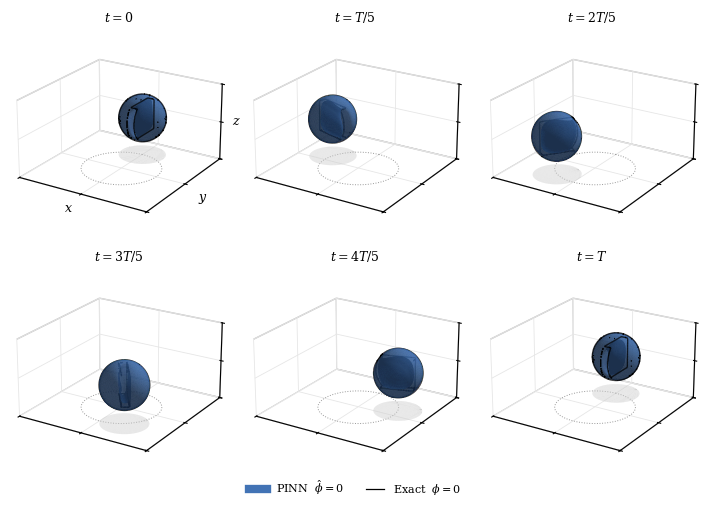

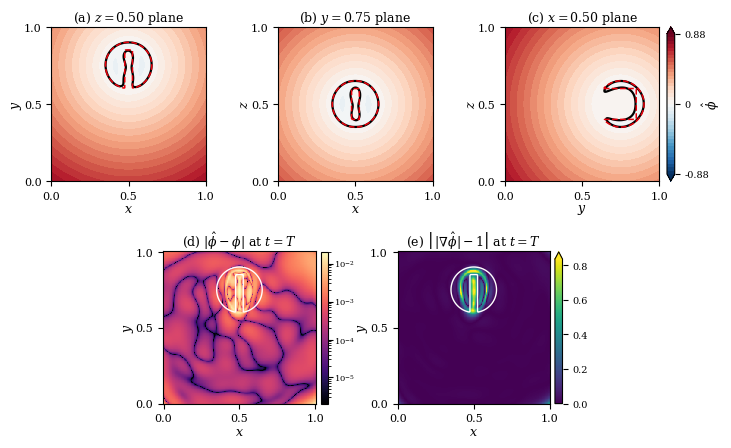

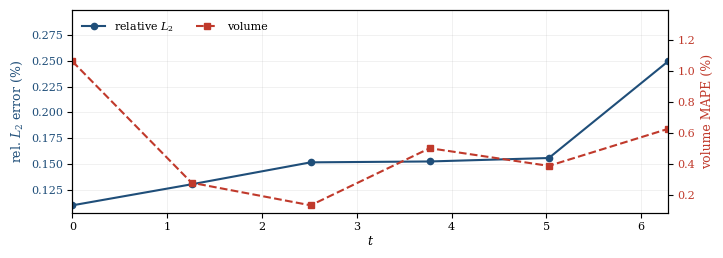

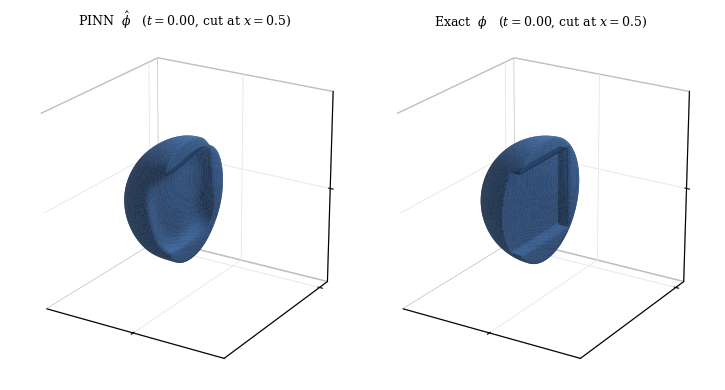

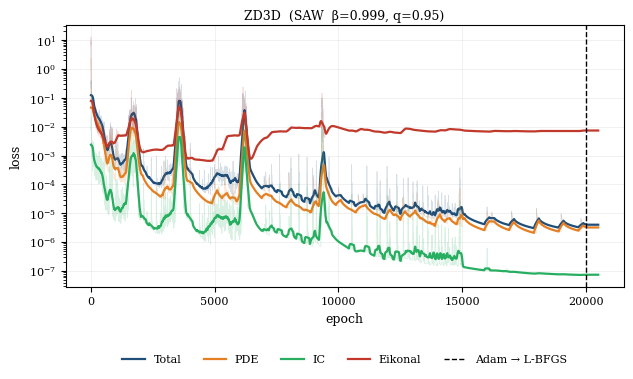

In [5]:
# --- figures -----------------------------------------------------------
import matplotlib.pyplot as plt

core.figure_interface(grid, times, tlabels, res['PHI_P'], res['PHI_E'],
                      savepath=f'{FIGDIR}/zd3d_interface')
plt.show()

core.figure_verification(grid, times, res, T_FINAL,
                         savepath=f'{FIGDIR}/zd3d_verification',
                         include_growth=False)
plt.show()

core.figure_growth(times, res, savepath=f'{FIGDIR}/zd3d_growth')
plt.show()

# cutaway at x = 0.5: the only view that shows the blind pocket
core.figure_cutaway(grid, res['PHI_P'], res['PHI_E'], times[0],
                    savepath=f'{FIGDIR}/zd3d_cutaway')
plt.show()

if 'history' in ck:
    core.figure_loss_history(ck['history'], ADAM_EPOCHS,
                             f'ZD3D  (SAW  \u03b2={BETA}, q={Q})',
                             savepath=f'{FIGDIR}/zd3d_loss_history')
    plt.show()
else:
    print('no loss history in this checkpoint — skipping zd3d_loss_history')

## Log the run

In [6]:
# --- append one row ----------------------------------------------------
import csv

_wh = ck.get('history', {})
row = {'algorithm': 'SAW', 'beta': BETA, 'q': Q,
       'seed': SEED,
       'final_w_pde': f"{_wh.get('w_pde', [float('nan')])[-1]:.4f}",
       'final_w_ic':  f"{_wh.get('w_ic',  [float('nan')])[-1]:.4f}",
       'final_w_eik': f"{_wh.get('w_eik', [float('nan')])[-1]:.4f}",
       'N_f': N_F, 'N_i': N_I, 'layers': LAYERS, 'neurons': NEURONS,
       'adam_epochs': ADAM_EPOCHS, 'lbfgs_epochs': LBFGS_EPOCHS,
       'scheduler': 'CosineAnnealingLR', 'eta_min': 1e-5,
       'grid_n': GRID_N, 't_normalized': True}

for i, t in enumerate(times):
    tag = f't{i}'
    row[f'L2abs_{tag}']  = f"{res['l2_abs'][i]:.3e}"
    row[f'L2rel_{tag}']  = f"{res['rel_L2'][i]:.4f}"
    row[f'volabs_{tag}'] = f"{res['vol_abs'][i]:.3e}"
    row[f'MAPE_{tag}']   = f"{res['vol_MAPE'][i]:.4f}"
    row[f'eikdev_{tag}'] = f"{res['eik_dev'][i]:.3e}"

row.update({'avg_L2abs':  f"{res['avg_l2_abs']:.3e}",
            'avg_L2rel':  f"{res['avg_rel_L2']:.4f}",
            'avg_volabs': f"{res['avg_vol_abs']:.3e}",
            'avg_MAPE':   f"{res['avg_vol_MAPE']:.4f}",
            'avg_eikdev': f"{res['avg_eik_dev']:.3e}",
            'minutes':    f"{ck.get('minutes', float('nan')):.2f}",
            'lbfgs_gain': f"{ck.get('lbfgs_gain', float('nan')):.3e}"})

new = not os.path.exists(CSV_PATH) or os.path.getsize(CSV_PATH) == 0
with open(CSV_PATH, 'a', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(row))
    if new:
        w.writeheader()
    w.writerow(row)
print('row appended →', CSV_PATH)

row appended → /content/drive/MyDrive/ZD3D/ZD3D_results.csv
